# Comparar

O mesmo modelo do caderno 02. Muda uma coisa por vez.

In [1]:
# Mesma limpeza e mesma separação do caderno 01.
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import pandas as pd
import mlflow
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

mlflow.set_tracking_uri("mlruns")
mlflow.set_experiment("churn")

dataset = pd.read_csv("dados/WA_Fn-UseC_-Telco-Customer-Churn.csv")
dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors="coerce")
dataset = dataset.dropna(subset=["TotalCharges"])
y = (dataset["Churn"] == "Yes").astype(int)

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
X = dataset[numericas + ["Contract"]]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

def avaliar(y_real, previsto):
    return {
        "acuracia": accuracy_score(y_real, previsto),
        "precisao": precision_score(y_real, previsto),
        "recall": recall_score(y_real, previsto),
        "f1": f1_score(y_real, previsto),
    }

/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/14 23:21:16 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


**v1**: limiar 0,5. É o modelo do caderno 02.

In [2]:
preparo = make_column_transformer(
    (StandardScaler(), numericas),
    (OneHotEncoder(), ["Contract"]),
)
modelo = make_pipeline(preparo, LogisticRegression(max_iter=1000))
modelo.fit(X_treino, y_treino)

# Probabilidade de sair, para cada cliente do teste. "Sai" se passar do limiar.
chance = modelo.predict_proba(X_teste)[:, 1]
previsto = (chance >= 0.5).astype(int)
metricas = avaliar(y_teste, previsto)
print(confusion_matrix(y_teste, previsto))
print({k: round(v, 3) for k, v in metricas.items()})

with mlflow.start_run(run_name="v1-limiar-0.5"):
    mlflow.log_params({"entradas": "tenure, MonthlyCharges, TotalCharges, Contract", "limiar": 0.5, "peso": "nenhum"})
    mlflow.log_metrics(metricas)
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/WA_Fn-UseC_-Telco-Customer-Churn.csv", name="churn"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")

[[1167  124]
 [ 248  219]]
{'acuracia': 0.788, 'precisao': 0.638, 'recall': 0.469, 'f1': 0.541}


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/14 23:21:21 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Antes da v2: o mesmo modelo, com três limiares. Quantos alertas cada um dispara?

In [3]:
# Alertas = clientes que o modelo marca como "sai".
for limiar in [0.7, 0.5, 0.3]:
    alerta = chance >= limiar
    pegou = (alerta & (y_teste == 1)).sum()
    print(f"limiar {limiar}: {alerta.sum()} alertas, {pegou} saíram de verdade (de {y_teste.sum()} que saíram)")
    print(f"   precisão {pegou / alerta.sum():.3f} | recall {pegou / y_teste.sum():.3f}")

limiar 0.7: 26 alertas, 21 saíram de verdade (de 467 que saíram)
   precisão 0.808 | recall 0.045
limiar 0.5: 343 alertas, 219 saíram de verdade (de 467 que saíram)
   precisão 0.638 | recall 0.469
limiar 0.3: 680 alertas, 352 saíram de verdade (de 467 que saíram)
   precisão 0.518 | recall 0.754


In [4]:
# Um cliente que muda de lado: posição 248 do teste.
print(X_teste.iloc[[248]])
print("probabilidade de sair:", round(chance[248], 2), "| real:", y_teste.iloc[248])
print("limiar 0,5 diz:", int(chance[248] >= 0.5), "| limiar 0,3 diz:", int(chance[248] >= 0.3))

      tenure  MonthlyCharges  TotalCharges        Contract
4213       6            50.8        288.05  Month-to-month
probabilidade de sair: 0.42 | real: 1
limiar 0,5 diz: 0 | limiar 0,3 diz: 1


**v2**: limiar 0,3. O mesmo modelo, corte mais baixo.

In [5]:
previsto = (chance >= 0.3).astype(int)
metricas = avaliar(y_teste, previsto)
print(confusion_matrix(y_teste, previsto))
print({k: round(v, 3) for k, v in metricas.items()})

with mlflow.start_run(run_name="v2-limiar-0.3"):
    mlflow.log_params({"entradas": "tenure, MonthlyCharges, TotalCharges, Contract", "limiar": 0.3, "peso": "nenhum"})
    mlflow.log_metrics(metricas)
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/WA_Fn-UseC_-Telco-Customer-Churn.csv", name="churn"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")

/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


[[963 328]
 [115 352]]
{'acuracia': 0.748, 'precisao': 0.518, 'recall': 0.754, 'f1': 0.614}


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/14 23:21:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


**v3**: volta ao limiar 0,5, mas com `class_weight="balanced"`: no treino, errar quem sai pesa mais.

In [6]:
preparo = make_column_transformer(
    (StandardScaler(), numericas),
    (OneHotEncoder(), ["Contract"]),
)
modelo = make_pipeline(preparo, LogisticRegression(max_iter=1000, class_weight="balanced"))
modelo.fit(X_treino, y_treino)

chance = modelo.predict_proba(X_teste)[:, 1]
previsto = (chance >= 0.5).astype(int)
metricas = avaliar(y_teste, previsto)
print(confusion_matrix(y_teste, previsto))
print({k: round(v, 3) for k, v in metricas.items()})

with mlflow.start_run(run_name="v3-peso-balanceado"):
    mlflow.log_params({"entradas": "tenure, MonthlyCharges, TotalCharges, Contract", "limiar": 0.5, "peso": "balanced"})
    mlflow.log_metrics(metricas)
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/WA_Fn-UseC_-Telco-Customer-Churn.csv", name="churn"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")

/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


[[884 407]
 [ 87 380]]
{'acuracia': 0.719, 'precisao': 0.483, 'recall': 0.814, 'f1': 0.606}


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/14 23:21:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Cada run gravou acurácia, precisão, recall e F1. O gráfico lê esses números de volta do MLflow. À esquerda, precisão e recall. À direita, F1 e acurácia.

tags.mlflow.runName  metrics.acuracia  metrics.precisao  metrics.recall  metrics.f1
      v1-limiar-0.5             0.788             0.638           0.469       0.541
      v2-limiar-0.3             0.748             0.518           0.754       0.614
 v3-peso-balanceado             0.719             0.483           0.814       0.606


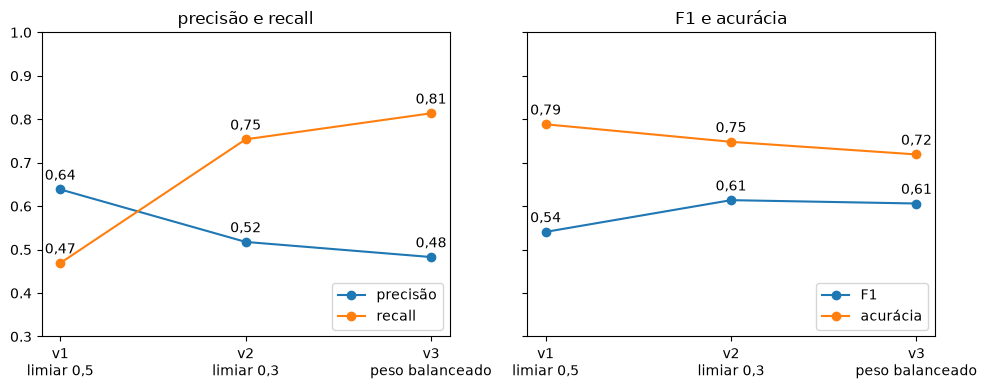

In [7]:
import matplotlib.pyplot as plt

runs = mlflow.search_runs(
    experiment_names=["churn"],
    filter_string="tags.mlflow.runName LIKE 'v%'",
    order_by=["start_time ASC"],
)
runs = runs.drop_duplicates("tags.mlflow.runName", keep="last")
colunas = ["metrics.acuracia", "metrics.precisao", "metrics.recall", "metrics.f1"]
print(runs[["tags.mlflow.runName"] + colunas].round(3).to_string(index=False))

nomes = ["v1\nlimiar 0,5", "v2\nlimiar 0,3", "v3\npeso balanceado"]
fig, (esq, direita) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, pares in [(esq, [("precisao", "precisão"), ("recall", "recall")]),
                  (direita, [("f1", "F1"), ("acuracia", "acurácia")])]:
    for coluna, rotulo in pares:
        valores = runs[f"metrics.{coluna}"].to_numpy()
        ax.plot(nomes, valores, marker="o", label=rotulo)
        for x, v in enumerate(valores):
            ax.annotate(f"{v:.2f}".replace(".", ","), (x, v), xytext=(0, 7), textcoords="offset points", ha="center")
    ax.legend(loc="lower right")
    ax.set_ylim(0.3, 1)
esq.set_title("precisão e recall")
direita.set_title("F1 e acurácia")
plt.tight_layout()
plt.savefig("img/g-evolucao.png", dpi=150, bbox_inches="tight")
plt.show()

Lendo o gráfico:

- v1 → v2: baixar o limiar de 0,5 para 0,3 fez o recall subir de 0,47 para 0,75. A precisão caiu de 0,64 para 0,52.
- v2 → v3: o peso balanceado pegou ainda mais gente que sai (recall 0,81), com precisão 0,48.
- A acurácia caiu nas duas mudanças (0,79 → 0,75 → 0,72). O F1 subiu (0,54 → 0,61 → 0,61).
- Qual versão usar depende de qual erro custa mais: perder um cliente ou ligar à toa.

`MLFLOW_ALLOW_FILE_STORE=true mlflow ui --backend-store-uri mlruns`